# Dataset description
## Car toll price by tollbooth in Colombia

**Source**: [instituo nacional de vias](https://inviasopendata-invias.opendata.arcgis.com/datasets/invias::peajesodagol/explore?location=2.656136%2C-70.731964%2C6)

# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from highlight_text import fig_text
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
import matplotlib.cm as cm
from pathlib import Path
import json

BASE_DIR = Path.cwd().parent.parent

## Load data

In [2]:
logo_path = BASE_DIR / "logo/logo.png"
path = "./data/PeajesODAGOL_5957561205438153209.csv"
path_geo = "./data/colombia_departments.geojson"

cols = ["Nombre del Peaje", "Categoría I", "x", "y"]

# utf-8-sig: the file starts with a BOM
df = pd.read_csv(path, encoding="utf-8-sig", usecols=cols)
logo = plt.imread(logo_path)

with open(path_geo, encoding="utf-8") as f:
    geo = json.load(f)

## Clean data

In [3]:
# Price 0 = not operating / no tariff for that category.
# "Latitud" holds the latitude twice, so x/y are used for the position.
tolls = (
    df[df["Categoría I"].gt(0)]
    .rename(columns={"Nombre del Peaje": "name", "Categoría I": "car"})
)
tolls["name"] = tolls["name"].str.strip()

print(len(tolls), "tollbooths with price")
print("Median car:", tolls["car"].median())
print(tolls.nlargest(5, "car")[["name", "car"]])
print(tolls.nsmallest(5, "car")[["name", "car"]])

172 tollbooths with price
Median car: 12700.0
         name    car
59    PIPIRAL  23000
149    GUAICO  21000
52     ABURRA  20600
34   El Korán  19900
44   CIRCASIA  19200
                 name   car
57   BAZURTO  (MANGA)  2300
56           CEBALLOS  2500
108            NIQUÍA  2500
159         LA PARADA  2700
72         LA HEROICA  2900


## Plot

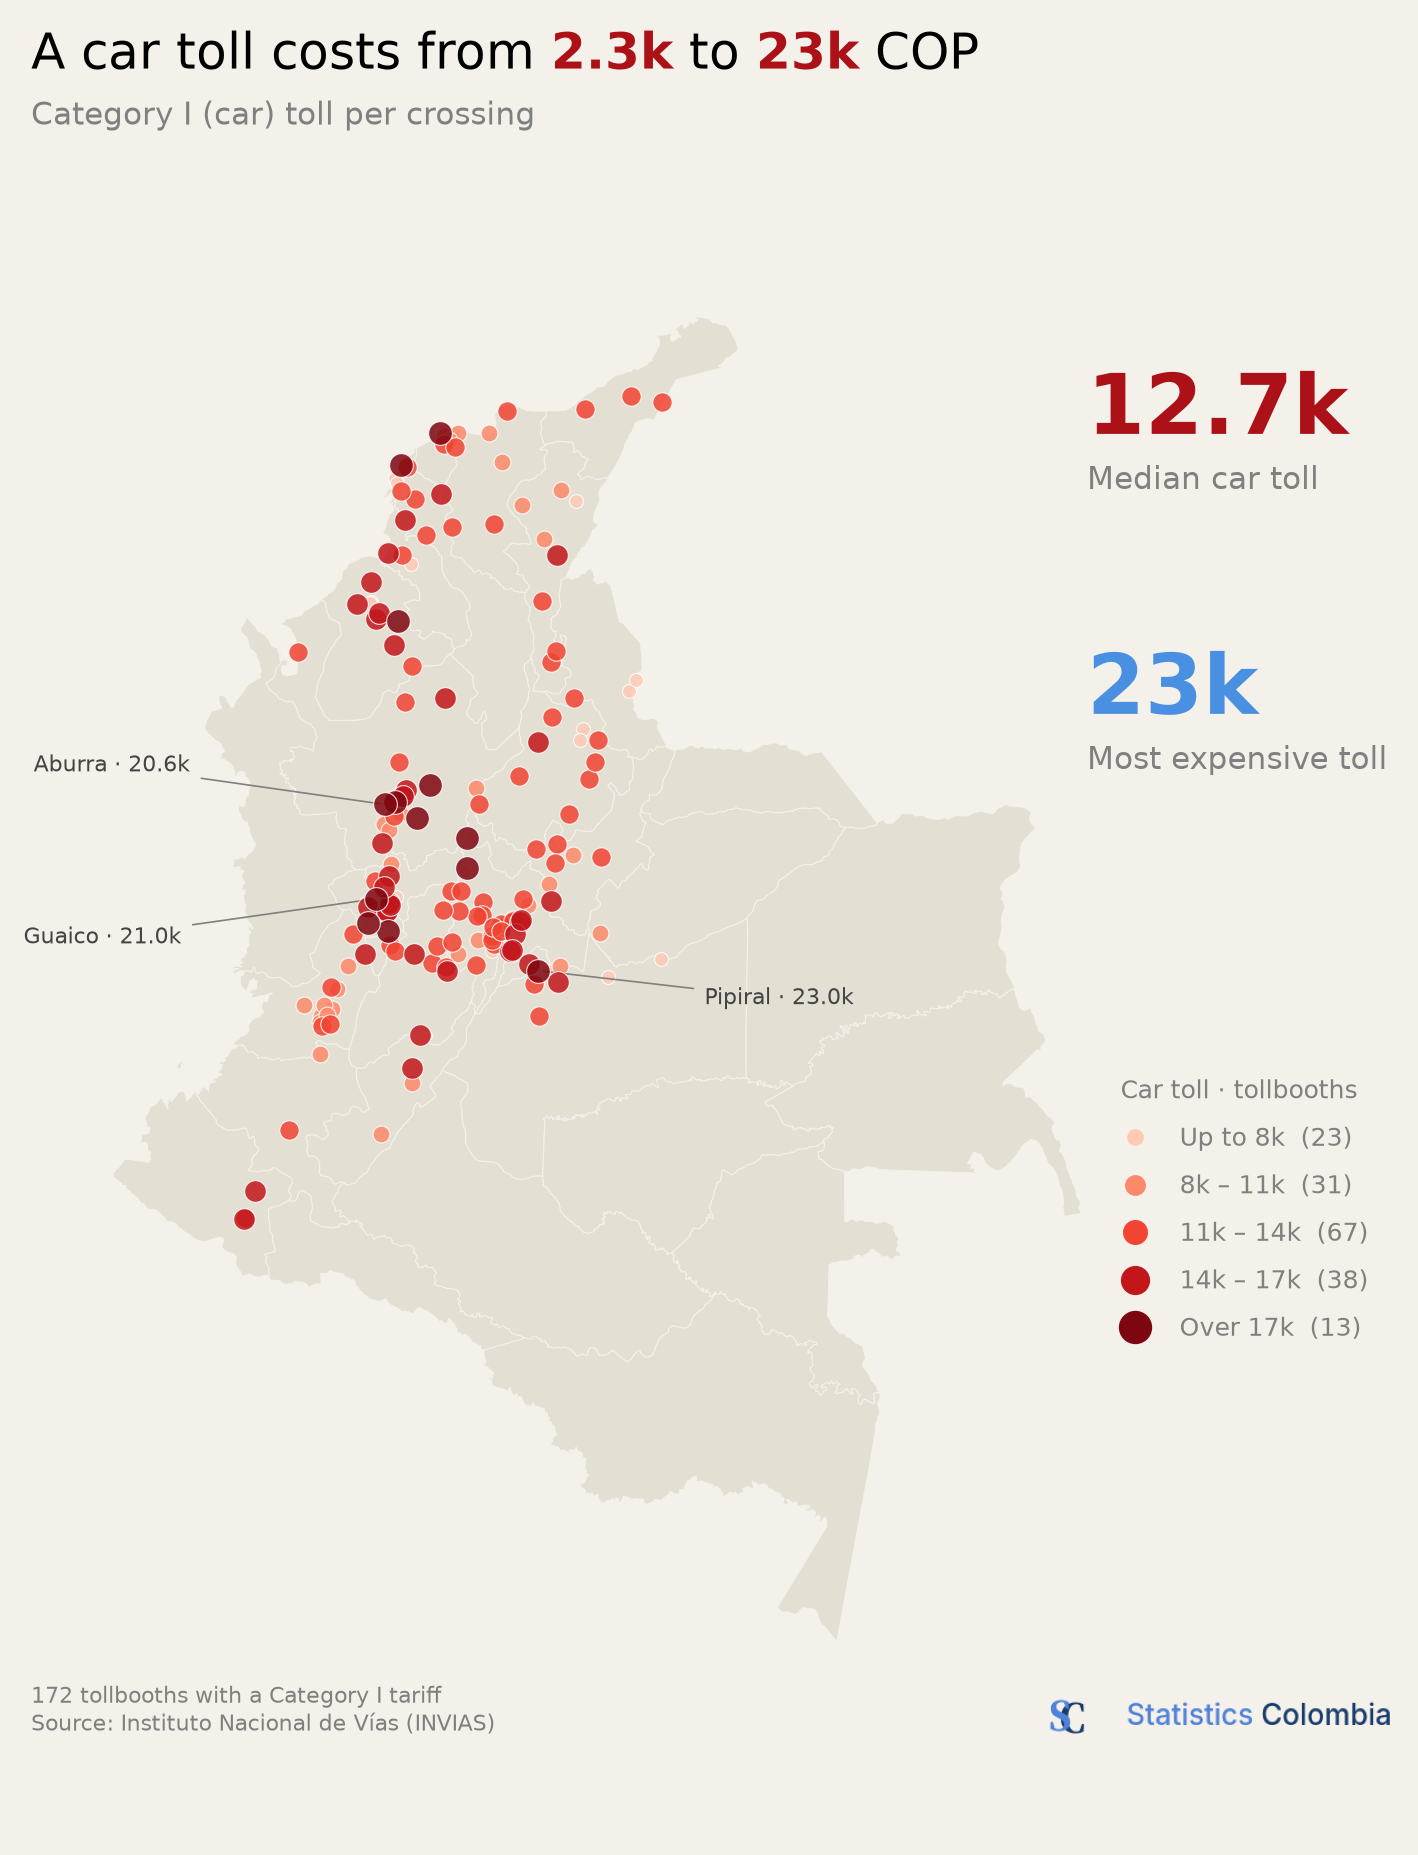

In [5]:
background = "#F4F1EA"
cmap = cm.Reds

bins = [0, 8000, 11000, 14000, 17000, float("inf")]
labels = ["Up to 8k", "8k – 11k", "11k – 14k", "14k – 17k", "Over 17k"]
shades = [0.2, 0.4, 0.6, 0.78, 0.95]
tolls["range"] = pd.cut(tolls["car"], bins=bins, labels=labels)

median_car = tolls["car"].median()
top = tolls.nlargest(1, "car").iloc[0]

fig, ax = plt.subplots(figsize=(8, 10), dpi=200)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

patches = [
    Polygon(poly[0], closed=True)
    for feat in geo["features"] if feat["properties"]["DPTO"] != "88"
    for poly in (
        [feat["geometry"]["coordinates"]]
        if feat["geometry"]["type"] == "Polygon"
        else feat["geometry"]["coordinates"]
    )
]
ax.add_collection(PatchCollection(
    patches, facecolor="#E4DFD3", edgecolor=background, linewidth=0.4))

# Cheapest first so the expensive tolls stay on top.
for i, (label, shade) in enumerate(zip(labels, shades)):
    group = tolls[tolls["range"].eq(label)]
    ax.scatter(
        group["x"], group["y"], s=25 + i * 12, color=cmap(shade),
        alpha=0.85, edgecolor="white", linewidth=0.4, zorder=2 + i,
    )

ax.set_xlim(-79.3, -66.8)
ax.set_ylim(-4.4, 12.8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_position([0.1, 0.08, 0.62, 0.8])

label_offsets = {"PIPIRAL": (60, -10), "GUAICO": (-70, -14), "ABURRA": (-70, 14)}
for _, t in tolls.nlargest(3, "car").iterrows():
    dx, dy = label_offsets[t["name"]]
    ax.annotate(
        f"{t['name'].title()} · {t['car'] / 1000:.1f}k",
        xy=(t["x"], t["y"]), xytext=(dx, dy), textcoords="offset points",
        fontsize=8, color="#444444", ha="left" if dx > 0 else "right",
        va="center",
        arrowprops={"arrowstyle": "-", "color": "gray", "linewidth": 0.6},
    )

fig_text(
    x=0.06, y=0.95,
    s=f"A car toll costs from <{tolls['car'].min() / 1000:.1f}k> to <{tolls['car'].max() / 1000:.0f}k> COP",
    highlight_textprops=[{"color": cmap(0.85), "weight": "bold"}] * 2,
    fontsize=18,
)
fig_text(
    x=0.06, y=0.915,
    s="Category I (car) toll per crossing",
    fontsize=11, color="gray",
)

fig_text(
    x=0.72, y=0.78,
    s=f"<{median_car / 1000:.1f}k>\nMedian car toll",
    highlight_textprops=[{"color": cmap(0.85), "weight": "bold", "fontsize": 30}],
    fontsize=11, color="gray",
)
fig_text(
    x=0.72, y=0.64,
    s=f"<{top['car'] / 1000:.0f}k>\nMost expensive toll",
    highlight_textprops=[{"color": "#4a90e2", "weight": "bold", "fontsize": 30}],
    fontsize=11, color="gray",
)

counts = tolls["range"].value_counts()
handles = [
    Line2D([], [], marker="o", linestyle="", color=cmap(shade),
           markersize=5 + i * 1.5, label=f"{label}  ({counts[label]})")
    for i, (label, shade) in enumerate(zip(labels, shades))
]
legend = fig.legend(
    handles=handles, title="Car toll · tollbooths", loc="center left",
    bbox_to_anchor=(0.72, 0.36), frameon=False, labelcolor="gray",
    title_fontproperties={"size": 9}, fontsize=9, labelspacing=0.9,
)
legend.get_title().set_color("gray")

fig.text(
    0.06, 0.1,
    f"{len(tolls)} tollbooths with a Category I tariff\n"
    "Source: Instituto Nacional de Vías (INVIAS)",
    fontsize=8, color="gray")

imagebox = OffsetImage(logo, zoom=0.4)
ab = AnnotationBbox(imagebox, xy=(0.77, 0.07), xycoords="figure fraction",
                    frameon=False, pad=0)
fig.add_artist(ab)

plt.show()